<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/6.%20Attention%20mechanism/2.%20Little%20deeper%20into%20attention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Differentiable Indexing on MNIST dataset

- I will write a blog about the importance and relevance of differentiable indexing in attention mechanism.
- Basically, it means see the attention as a lookup table, where queries and keys are learned in a NN to select the next value.
- In this selection, if the queries and keys are discrete (fixed scalar value), NN cannot learn anything about the queries and keys.
- so, we use a differentiable indexing where the queries and keys and vectors and we replace the exact matching with a similarity score.
- In the output, we pick a value with a little bit of all the values (a weighted sum of all the values), with huge weight assigned to the value close to the actual value.

- We will see this demonstration of this concept using MNIST dataset

In [101]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.utils.data.dataloader as dataloader

import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from pathlib import Path

## Get the dataset

- Hard Indexing


In [102]:
data_dir = Path("../assets/datasets")  # I'm just using the previous path from codespaces.

# we will select only 100 images to work with in this tutorial
n_images = 100

#we define a transfor to normalise and convert to tensor while downloading our dataset.
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.1307],[0.3081])   # since we know our mean and std from earlier notebooks
])

#Load our dataset.
dataset = datasets.MNIST(
    data_dir,
    train = True,
    transform=image_transform,
    download=True
)

In [103]:
# select random indices from our dataset.
rand_idx = torch.randint(dataset.data.shape[0], (n_images,))
# print(rand_idx)

#extract the images and concatnate them into a single tensor.
dataset_tensor = torch.cat([dataset.data[i].unsqueeze(0) for i in rand_idx])

dataset shape is:  torch.Size([100, 28, 28])


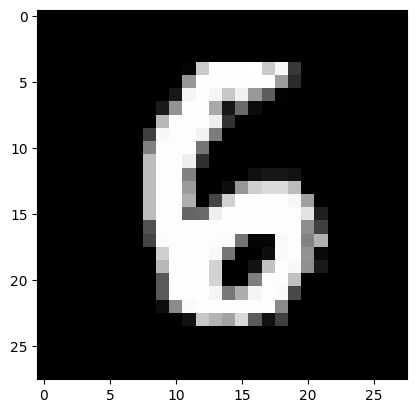

In [104]:
print('dataset shape is: ',dataset_tensor.shape)

#show one image
id = 10
plt.imshow(dataset_tensor[id].numpy(), cmap = 'gray')

- As we can see, I have used a hardcoded indexing to show the image 'id = 10'
- Now we will see how we can index the same image with **Matrix Multiplication**

## Indexing Dataset using Matrix Multiplication

### using one hot encoding
- We can perform multiplication of **one hot encodeing** our index, we call this query.
  - Meaning, our index 10 will he one hot encoded to a dim of 100 (our dataset len) --> (1* 100)
- Then this one hot encoding is multiplied to another one hot encoding called key.
  - The key is the one hot encoding of 100 numbers to 100 classes (dataset length) (100*100 matrix).
  - we use a Transpose of Key to multiply to query
- Then the resulting output as called an attention map (attention score if 1D) is multiplied with the dataset tensor to get our image out!!

In [105]:
query = F.one_hot(torch.tensor([id]), n_images)   #creates a 1*100 vector
print(f'shape of query is: {query.shape}')

#now key
key = F.one_hot(torch.arange(n_images), n_images) # 100*100
print(f'shape of key is: {key.shape}')

attention_map = torch.mm(query, key.t())
print(f'shape of attention map is: {attention_map.shape}')

output = torch.mm(attention_map.float(), dataset_tensor.reshape(100,-1).float())
print(f'shape of the outpur is : {output.shape}')

shape of query is: torch.Size([1, 100])
shape of key is: torch.Size([100, 100])
shape of attention map is: torch.Size([1, 100])
shape of the outpur is : torch.Size([1, 784])


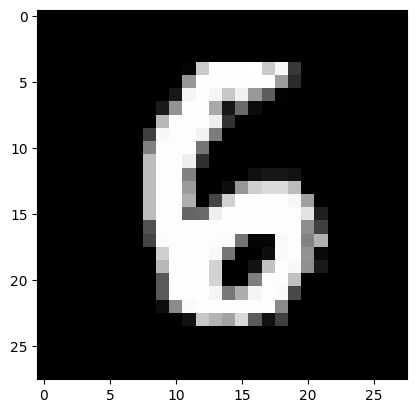

In [106]:
# we can see the image now
plt.imshow(output.reshape(28,28).numpy(), cmap = 'gray')

- We have successfully extracted our target image using matrix multiplication
- However, we are still using discrete values (1s and 0s).
- Now we will explore how we can do the same as a **soft look up** (as mentioned a weighted sum of all the dataset tensor images but with more weight to the right image or the target image!!)

### Attention as a 'Soft' Look-up

In [107]:
#size of the vector that we want our q and keys to be
vec_size =512

q_rand_vec = torch.randn(1, vec_size)   #(1,512)

keys_rand_vec = torch.randn(n_images, vec_size)   #transposed-->(512, 100)

attention_map = torch.mm(q_rand_vec, keys_rand_vec.t()).float()   #(1,100)

# now the important thing is to pass the attention map through a softmax function
# this will make our attention map as probability distribution over all the dataset
# but the sum would be equal to 1
attention_weights = F.softmax(attention_map, dim =1)

# we can explore the attention weights
print(f'shape of our attention map is: {attention_map.shape}')
print(f'shape of our attention weights is: {attention_weights.shape}')
print(f'probability distribution over the dataset is: {attention_weights.sum()}')
#since they are floats, the sum will be very near to 1


shape of our attention map is: torch.Size([1, 100])
shape of our attention weights is: torch.Size([1, 100])
probability distribution over the dataset is: 0.9999999403953552


In [108]:
# we can also see the max value that the softmax assigned to an index
print(f'Highest value (probability) assignes to an index is: {attention_weights.max().item() *100:.2f}')
print(f'the index at which the max value is assigned is at: {attention_weights.argmax()}')

Highest value (probability) assignes to an index is: 99.63
the index at which the max value is assigned is at: 2


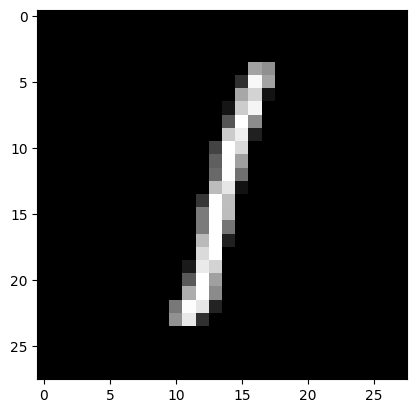

In [109]:
# using attention weights we can noe calculate the weighted sum of all the inputs (Indexing in our case)
output = torch.mm(attention_weights, dataset_tensor.reshape(100,-1).float())

plt.imshow(output.reshape(28,28).numpy(), cmap = 'gray')

- The image above shows that output as the probability distribution over the whole dataset.
- We can also add multiples queries, instead of '1', we just have to initiate our query, keys with higher number.

### Multiple Queries instead of one

In [110]:
#size of the vector that we want our q and keys to be
vec_size = 512

num_q = 5

q_rand_vec = torch.randn(num_q, vec_size)   #(5,512)

keys_rand_vec = torch.randn(n_images, vec_size)   #transposed-->(512, 100)

attention_map = torch.mm(q_rand_vec, keys_rand_vec.t()).float()   #(5,100)

# dim = -1 since our attention map is now [5,100] we want al
attention_weights = F.softmax(attention_map, dim = -1)

# we can explore the attention weights
print(f'shape of our attention map is: {attention_map.shape}')
print(f'shape of our attention weights is: {attention_weights.shape}')
print(f'probability distribution over the dataset is: {attention_weights.sum(dim =1)}')
#since they are floats, the sum will be very near to 1


shape of our attention map is: torch.Size([5, 100])
shape of our attention weights is: torch.Size([5, 100])
probability distribution over the dataset is: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [111]:
# we can also see the max value that the softmax assigned to an index
print(f'Highest value (probability) assignes to an index is: {attention_weights.max(dim = 1)}')

Highest value (probability) assignes to an index is: torch.return_types.max(
values=tensor([0.7260, 0.7201, 0.5575, 0.9508, 1.0000]),
indices=tensor([30,  4, 14, 88,  5]))


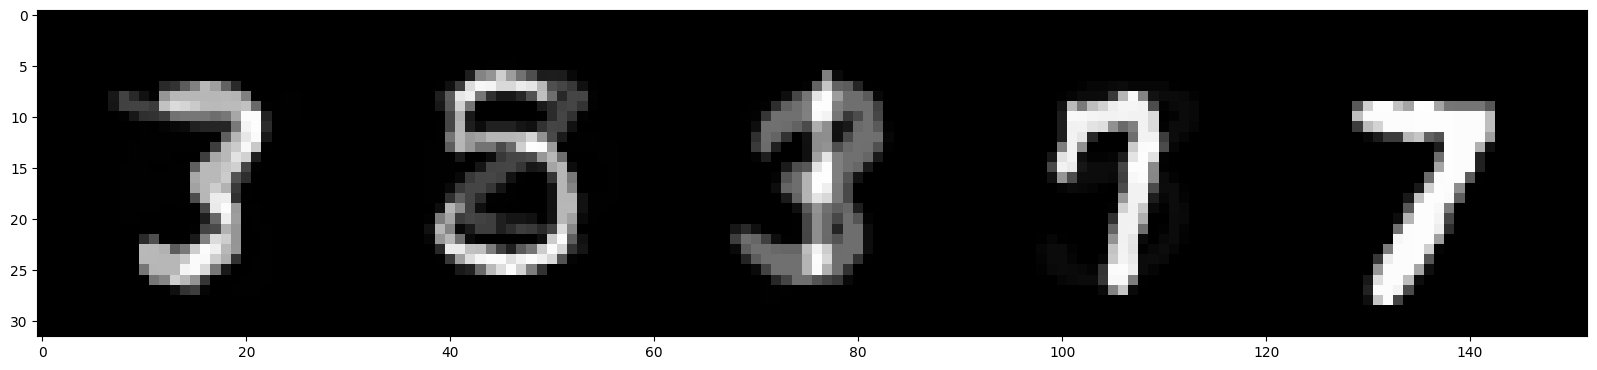

In [112]:
# using attention weights we can noe calculate the weighted sum of all the inputs (Indexing in our case)
output = torch.mm(attention_weights, dataset_tensor.reshape(100,-1).float())

# Lets visualise an entire batch of images!
plt.figure(figsize = (20,10))
out = torchvision.utils.make_grid(output.reshape(num_q, 1, 28, 28), 8, normalize=True)
plt.imshow(out.numpy().transpose((1, 2, 0)))

- we can also have multiple batches of multiple queries.
- meaning, we can calculate attention (indexing in our case) for n batches parallely, with multiple queries in each batch.

### Multi head Attention (Multi batch queries)

- It is similar except we initiate the tensors with 3 dimensions

In [113]:
#size of the vector that we want our q and keys to be
vec_size = 512

num_q = 5

n_heads = 4

q_rand_vec = torch.randn(n_heads ,num_q, vec_size)   #(4,5,512)

keys_rand_vec = torch.randn(n_heads, n_images, vec_size)   #transposed(1,2)-->(4,512, 100)

#since we use batches, we use torch.bmm() batched matrix multiplication
attention_map = torch.bmm(q_rand_vec, keys_rand_vec.transpose(1,2)).float()   #(4,5,100)

# dim = -1 since our attention map is now [5,100] we want al
attention_weights = F.softmax(attention_map, dim = -1)

# we can explore the attention weights
print(f'shape of our attention map is: {attention_map.shape}')
print(f'shape of our attention weights is: {attention_weights.shape}')
print(f'probability distribution over the dataset is: {attention_weights.sum(dim = -1)}')  #sum along the last dim(no.of images)
#since they are floats, the sum will be very near to 1


shape of our attention map is: torch.Size([4, 5, 100])
shape of our attention weights is: torch.Size([4, 5, 100])
probability distribution over the dataset is: tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000, 1.0000, 1.0000]])


In [114]:
'''
To perform bmm between attention weights and dataset tensor, we have to change the shape of the dataset tensor
1. we have to make the [100, 28,28] into first [100, 784] then we have to unsqueeze at dim 0 to make it a 3d tensor
2. We have to make multiple copies of the dataset for each head
  - we can achieve this without copyinng the dataset multiple times
  - using .expand() will make multiple pointers to the sae dataset
  - we expand the dataset to match n_heads(4), n_images(100) already our data has it as 100, the -1 at
  the end specifies not to change the dimension of features
'''
output = torch.bmm(attention_weights, dataset_tensor.reshape(100,784).unsqueeze(0).expand(n_heads, n_images, -1).float())

print(f'shape of the output for multihead attention is: {output.shape}')

shape of the output for multihead attention is: torch.Size([4, 5, 784])


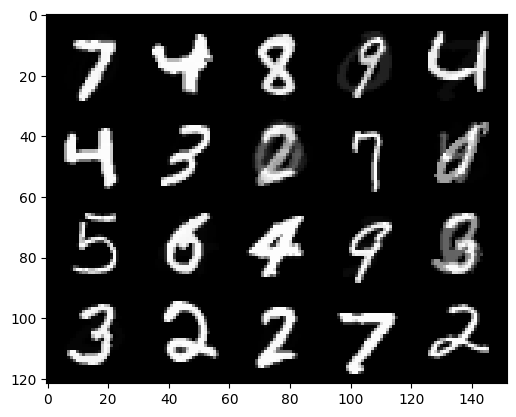

In [115]:
output_reshape = output.reshape(n_heads * num_q, 1, 28,28)

grid = torchvision.utils.make_grid(output_reshape, nrow = num_q, normalize = True)
plt.imshow(grid.permute(1,2,0))  #(height, width, channel) for matplotlib

### let us make a function to explore the vec_size variable

- The important variable vec_size has a huge impact on how the weighted sum is distributed over the dataset.
- we will make a function and experiment how changing the vec_size variable infulence the output

In [116]:
def multi_query_attention(vec_size, num_q):

  q_rand_vec = torch.randn(num_q, vec_size)

  keys_rand_vec = torch.randn(n_images, vec_size)

  attention_map = torch.mm(q_rand_vec, keys_rand_vec.t()).float()

  attention_weights = F.softmax(attention_map, dim = -1)

  output = torch.mm(attention_weights, dataset_tensor.reshape(100,-1).float())

  return output

In [117]:
out1 = multi_query_attention(32, 5)
out2 = multi_query_attention(64, 5)
out3 = multi_query_attention(132, 5)
out4 = multi_query_attention(215, 5)

In [118]:
#stack all the tensors
all_out = torch.stack([out1, out2,out3,out4], dim = 0)
print(all_out.shape)

# notice the shape of the stacked tensors is same as our multi head multi query attention output!!

torch.Size([4, 5, 784])


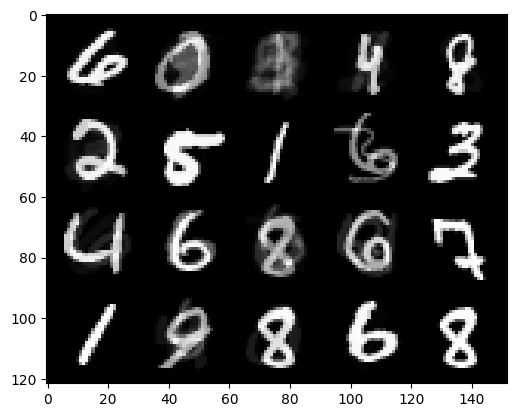

In [119]:
all_out_reshape = all_out.reshape(all_out.shape[0] * all_out.shape[1], 1, 28,28)

grid = torchvision.utils.make_grid(all_out_reshape, nrow = 5, normalize = True)
plt.imshow(grid.permute(1,2,0))  #(height, width, channel) for matplotlib

- The above implementation already has a pytorch equivalent implementation.
- We will now see the **pytorch** implementation of the **MultiHead attention**

## Pytorch Multi Head Attention